# Preprocess Data

## Preparing Data

In [ ]:
import pandas as pd
import numpy as np


In [ ]:
mbg = pd.read_csv("mbg.csv")

mbg.head()

,conversation_id_str,created_at,favorite_count,full_text,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,retweet_count,tweet_url,user_id_str,username
0,1906394314026148203,Sun Mar 30 23:58:42 +0000 2025,0,@hexagrap_id Walau banjir distribusi MBG tetap...,1906496338357067826,NaN,hexagrap_id,in,NaN,0,0,0,https://x.com/undefined/status/190649633835706...,1694955370048028672,NaN
1,1906394314026148203,Sun Mar 30 23:57:37 +0000 2025,0,@hexagrap_id Presiden dan program MBG satu hat...,1906496065119162836,NaN,hexagrap_id,in,NaN,0,0,0,https://x.com/undefined/status/190649606511916...,1694988519624826880,NaN
2,1906394314026148203,Sun Mar 30 23:57:28 +0000 2025,0,@hexagrap_id Surat presiden: program MBG harus...,1906496028217582074,NaN,hexagrap_id,in,NaN,0,0,0,https://x.com/undefined/status/190649602821758...,1702537721611440128,NaN
3,1906394034979196928,Sun Mar 30 23:57:18 +0000 2025,0,@LeonPriceleon48 Warga tak perlu cemas Preside...,1906495984043163656,NaN,LeonPriceleon48,in,NaN,0,0,0,https://x.com/undefined/status/190649598404316...,1702588250416967680,NaN
4,1906394314026148203,Sun Mar 30 23:57:10 +0000 2025,0,@hexagrap_id Warga terdampak banen merencanaka...,1906495952212709779,NaN,hexagrap_id,in,NaN,0,0,0,https://x.com/undefined/status/190649595221270...,1696016602746208256,NaN


## Duplicate

In [ ]:
mbg.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4519 entries, 0 to 4518
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   conversation_id_str      4519 non-null   int64  
 1   created_at               4519 non-null   object 
 2   favorite_count           4519 non-null   int64  
 3   full_text                4519 non-null   object 
 4   id_str                   4519 non-null   int64  
 5   image_url                800 non-null    object 
 6   in_reply_to_screen_name  3277 non-null   object 
 7   lang                     4519 non-null   object 
 8   location                 0 non-null      float64
 9   quote_count              4519 non-null   int64  
 10  reply_count              4519 non-null   int64  
 11  retweet_count            4519 non-null   int64  
 12  tweet_url                4519 non-null   object 
 13  user_id_str              4519 non-null   int64  
 14  username                

In [ ]:
mbg.drop_duplicates(subset ="full_text", keep = 'first', inplace = True)

In [ ]:
mbg.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4494 entries, 0 to 4518
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   conversation_id_str      4494 non-null   int64  
 1   created_at               4494 non-null   object 
 2   favorite_count           4494 non-null   int64  
 3   full_text                4494 non-null   object 
 4   id_str                   4494 non-null   int64  
 5   image_url                800 non-null    object 
 6   in_reply_to_screen_name  3255 non-null   object 
 7   lang                     4494 non-null   object 
 8   location                 0 non-null      float64
 9   quote_count              4494 non-null   int64  
 10  reply_count              4494 non-null   int64  
 11  retweet_count            4494 non-null   int64  
 12  tweet_url                4494 non-null   object 
 13  user_id_str              4494 non-null   int64  
 14  username                 0 no

## Wordcloud

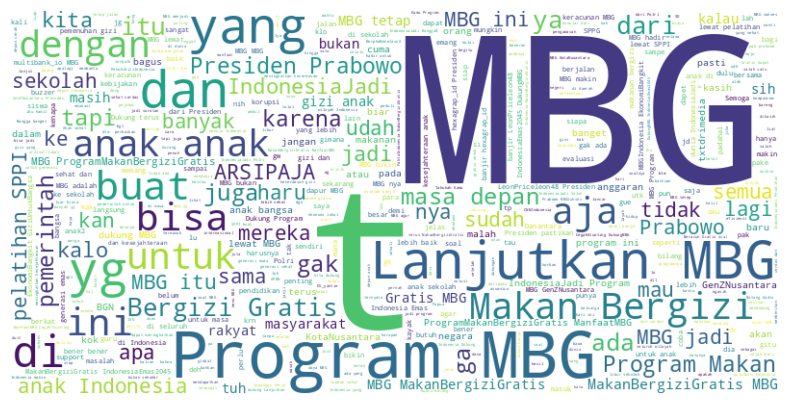

In [ ]:
import pandas as pd
import numpy as np
from PIL import Image
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt

mbg['full_text'] = mbg['full_text'].fillna('')

text = ' '.join(mbg['full_text'].astype(str).tolist())

stopwords = set(STOPWORDS)
stopwords.update(['https', 'co', 'RT', '...', 'amp'])

wc = WordCloud(stopwords=stopwords, background_color="white", max_words=500, width=800, height=400)

wc.generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis("off")
plt.show()

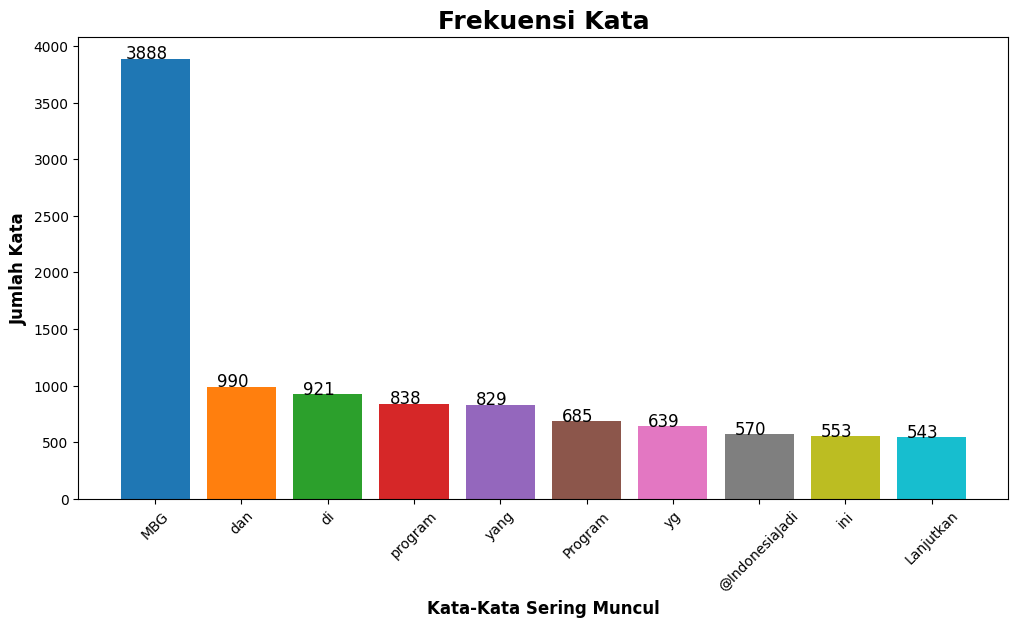

In [ ]:
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd

# Menggunakan dataframe yang sudah ada
text = " ".join(mbg['full_text'])

tokens = text.split()
word_counts = Counter(tokens)

top_words = word_counts.most_common(10)
word, count = zip(*top_words)
colors =plt.cm.tab10(range(len(word)))

plt.figure(figsize=(12, 6))
bars = plt.bar(word, count, color=colors)
plt.xlabel("Kata-Kata Sering Muncul", fontsize=12, fontweight='bold')
plt.ylabel("Jumlah Kata", fontsize=12, fontweight='bold')
plt.title("Frekuensi Kata", fontsize=18, fontweight='bold')
plt.xticks(rotation=45)

# Menambahkan angka rata tengah di atas setiap bar
for bar, num in zip(bars, count):
  plt.text(bar.get_x() + bar.get_width() / 2 - 0.1, num + 1, str(num), fontsize=12, color='black', ha='center')

plt.show()

## Character Removal

In [ ]:
import re
import string


# Fungsi untuk menghapus URL
def remove_URL(tweet):
    if tweet is not None and isinstance(tweet, str):
        url = re.compile(r'https?://\S+|www\.\S+')
        return url.sub(r'', tweet)
    else:
        return tweet

# Fungsi untuk menghapus HTML
def remove_html(tweet):
    if tweet is not None and isinstance(tweet, str):
        html = re.compile(r'<.*?>')
        return html.sub(r'', tweet)
    else:
        return tweet

# Fungsi untuk menghapus emoji
def remove_emoji(tweet):
    if tweet is not None and isinstance(tweet, str):
        emoji_pattern = re.compile("["
            u"\U0001F600-\U0001F64F"  # emoticons
            u"\U0001F300-\U0001F5FF"  # symbols & pictographs
            u"\U0001F680-\U0001F6FF"  # transport & map symbols
            u"\U0001F700-\U0001F77F"  # alchemical symbols
            u"\U0001F780-\U0001F7FF"  # Geometric Shapes Extended
            u"\U0001F800-\U0001F8FF"  # Supplemental Arrows-C
            u"\U0001F900-\U0001F9FF"  # Supplemental Symbols and Pictographs
            u"\U0001FA00-\U0001FA6F"  # Chess Symbols
            u"\U0001FA70-\U0001FAFF"  # Symbols and Pictographs Extended-A
            u"\U0001F004-\U0001F0CF"  # Additional emoticons
            u"\U0001F1E0-\U0001F1FF"  # flags
                               "]+", flags=re.UNICODE)
        return emoji_pattern.sub(r'', tweet)
    else:
        return tweet

# Fungsi untuk menghapus simbol
def remove_symbols(tweet):
    if tweet is not None and isinstance(tweet, str):
        tweet = re.sub(r'[^a-zA-Z0-9\s]', '', tweet)
    return tweet

# Fungsi untuk menghapus angka
def remove_numbers(tweet):
    if tweet is not None and isinstance(tweet, str):
        tweet = re.sub(r'\d', '', tweet)
    return tweet

# Fungsi hapus username
def remove_usernames(text):
    return re.sub(r'@\w+', '', text)

mbg['cleaning'] = mbg['full_text'].apply(lambda x: remove_URL(x))
mbg['cleaning'] = mbg['cleaning'].apply(lambda x: remove_usernames(x))
mbg['cleaning'] = mbg['cleaning'].apply(lambda x: remove_html(x))
mbg['cleaning'] = mbg['cleaning'].apply(lambda x: remove_emoji(x))
mbg['cleaning'] = mbg['cleaning'].apply(lambda x: remove_symbols(x))
mbg['cleaning'] = mbg['cleaning'].apply(lambda x: remove_numbers(x))

mbg.head(10)

,conversation_id_str,created_at,favorite_count,full_text,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,retweet_count,tweet_url,user_id_str,username,cleaning
0,1906394314026148203,Sun Mar 30 23:58:42 +0000 2025,0,@hexagrap_id Walau banjir distribusi MBG tetap...,1906496338357067826,NaN,hexagrap_id,in,NaN,0,0,0,https://x.com/undefined/status/190649633835706...,1694955370048028672,NaN,Walau banjir distribusi MBG tetap lancar kata...
1,1906394314026148203,Sun Mar 30 23:57:37 +0000 2025,0,@hexagrap_id Presiden dan program MBG satu hat...,1906496065119162836,NaN,hexagrap_id,in,NaN,0,0,0,https://x.com/undefined/status/190649606511916...,1694988519624826880,NaN,Presiden dan program MBG satu hati pastikan d...
2,1906394314026148203,Sun Mar 30 23:57:28 +0000 2025,0,@hexagrap_id Surat presiden: program MBG harus...,1906496028217582074,NaN,hexagrap_id,in,NaN,0,0,0,https://x.com/undefined/status/190649602821758...,1702537721611440128,NaN,Surat presiden program MBG harus hadir di wil...
3,1906394034979196928,Sun Mar 30 23:57:18 +0000 2025,0,@LeonPriceleon48 Warga tak perlu cemas Preside...,1906495984043163656,NaN,LeonPriceleon48,in,NaN,0,0,0,https://x.com/undefined/status/190649598404316...,1702588250416967680,NaN,Warga tak perlu cemas Presiden punya solusi a...
4,1906394314026148203,Sun Mar 30 23:57:10 +0000 2025,0,@hexagrap_id Warga terdampak banen merencanaka...,1906495952212709779,NaN,hexagrap_id,in,NaN,0,0,0,https://x.com/undefined/status/190649595221270...,1696016602746208256,NaN,Warga terdampak banen merencanakan penyaluran...
5,1906394034979196928,Sun Mar 30 23:56:22 +0000 2025,0,@LeonPriceleon48 Wilayah banjir tetap didukung...,1906495748528812211,NaN,LeonPriceleon48,in,NaN,0,0,0,https://x.com/undefined/status/190649574852881...,1689171893654556673,NaN,Wilayah banjir tetap didukung Program MBG ga ...
6,1906394314026148203,Sun Mar 30 23:54:53 +0000 2025,0,@hexagrap_id Presiden pastikan ketersediaan MB...,1906495377349718500,NaN,hexagrap_id,in,NaN,0,0,0,https://x.com/undefined/status/190649537734971...,1684489290687074312,NaN,Presiden pastikan ketersediaan MBG meski terj...
7,1906394034979196928,Sun Mar 30 23:54:32 +0000 2025,0,@LeonPriceleon48 Presiden bawa support pastiin...,1906495288925475285,NaN,LeonPriceleon48,in,NaN,0,0,0,https://x.com/undefined/status/190649528892547...,1848930840304381952,NaN,Presiden bawa support pastiin program MBG tet...
8,1906394034979196928,Sun Mar 30 23:54:24 +0000 2025,0,@LeonPriceleon48 Presiden pastikan distribusi ...,1906495257434558494,NaN,LeonPriceleon48,in,NaN,0,0,0,https://x.com/undefined/status/190649525743455...,1696053013692211200,NaN,Presiden pastikan distribusi MBG aman dari da...
9,1906394314026148203,Sun Mar 30 23:54:22 +0000 2025,0,@hexagrap_id Daerah terdampak banjir jangan kh...,1906495246659404057,NaN,hexagrap_id,in,NaN,0,0,0,https://x.com/undefined/status/190649524665940...,1696067555230941184,NaN,Daerah terdampak banjir jangan khawatir presi...


In [ ]:
mbg[['full_text', 'cleaning']].head(10)

,full_text,cleaning
0,@hexagrap_id Walau banjir distribusi MBG tetap...,Walau banjir distribusi MBG tetap lancar kata...
1,@hexagrap_id Presiden dan program MBG satu hat...,Presiden dan program MBG satu hati pastikan d...
2,@hexagrap_id Surat presiden: program MBG harus...,Surat presiden program MBG harus hadir di wil...
3,@LeonPriceleon48 Warga tak perlu cemas Preside...,Warga tak perlu cemas Presiden punya solusi a...
4,@hexagrap_id Warga terdampak banen merencanaka...,Warga terdampak banen merencanakan penyaluran...
5,@LeonPriceleon48 Wilayah banjir tetap didukung...,Wilayah banjir tetap didukung Program MBG ga ...
6,@hexagrap_id Presiden pastikan ketersediaan MB...,Presiden pastikan ketersediaan MBG meski terj...
7,@LeonPriceleon48 Presiden bawa support pastiin...,Presiden bawa support pastiin program MBG tet...
8,@LeonPriceleon48 Presiden pastikan distribusi ...,Presiden pastikan distribusi MBG aman dari da...
9,@hexagrap_id Daerah terdampak banjir jangan kh...,Daerah terdampak banjir jangan khawatir presi...


## Case Folding

In [ ]:
# ------ Case Folding --------
# Using Series.str.lower() function on Pandas
mbg['Text Case Folding'] = mbg['cleaning'].str.lower()


mbg[['cleaning', 'Text Case Folding']].head(10)

,cleaning,Text Case Folding
0,Walau banjir distribusi MBG tetap lancar kata...,walau banjir distribusi mbg tetap lancar kata...
1,Presiden dan program MBG satu hati pastikan d...,presiden dan program mbg satu hati pastikan d...
2,Surat presiden program MBG harus hadir di wil...,surat presiden program mbg harus hadir di wil...
3,Warga tak perlu cemas Presiden punya solusi a...,warga tak perlu cemas presiden punya solusi a...
4,Warga terdampak banen merencanakan penyaluran...,warga terdampak banen merencanakan penyaluran...
5,Wilayah banjir tetap didukung Program MBG ga ...,wilayah banjir tetap didukung program mbg ga ...
6,Presiden pastikan ketersediaan MBG meski terj...,presiden pastikan ketersediaan mbg meski terj...
7,Presiden bawa support pastiin program MBG tet...,presiden bawa support pastiin program mbg tet...
8,Presiden pastikan distribusi MBG aman dari da...,presiden pastikan distribusi mbg aman dari da...
9,Daerah terdampak banjir jangan khawatir presi...,daerah terdampak banjir jangan khawatir presi...


## Stopword

In [ ]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
list_stopwords = stopwords.words('indonesian')


# ---------------------------- manualy add stopword  ------------------------------------
# append additional stopword
list_stopwords.extend(["yg", "dg", "rt", "dgn", "ny", 'klo',
                       'kalo', 'amp', 'biar', 'bikin', 'bilang',
                       'gak', 'ga', 'krn', 'nya', 'nih', 'sih',
                       'si', 'tau', 'tdk', 'tuh', 'utk', 'ya',
                       'jd', 'jgn', 'sdh', 'aja',
                       'nyg', 'hehe', 'pen', 'u', 'nan', 'loh', 'rt',
                       '&amp', 'yah', 'sdgkan', 'sdg', 'emg', 'sm', 'pls', 'mlu', 'ken',
                       'allah', 'brb', 'btw', 'b/c', 'cod', 'cmiiw', 'fyi',
                       'gg', 'ggwp', 'idk', 'ikr', 'lol', 'ootd', 'lmao', 'oot',
                       'pap', 'otw', 'tfl', 'vc', 'ygy'])

# ----------------------- add stopword from txt file ------------------------------------
# read txt stopword using pandas
txt_stopword = pd.read_csv("stopwordbahasa.txt", names= ["stopwords"], header = None)

# convert stopword string to list & append additional stopword
list_stopwords.extend(txt_stopword["stopwords"][0].split(' '))

# ---------------------------------------------------------------------------------------

# convert list to dictionary
list_stopwords = set(list_stopwords)


#remove stopword pada list token
def stopwords_removal(words):
  if isinstance(words, str):  # jika input adalah string
    words = words.split()   # tokenisasi sederhana

  return [word for word in words if word not in list_stopwords]



In [ ]:
# mbg['Text Filtering'] = mbg['Text Case Folding'].apply(stopwords_removal)

mbg['Text Filtering'] = mbg['Text Case Folding'].apply(
    lambda x: ' '.join(stopwords_removal(x))
)

In [ ]:
mbg[['Text Case Folding', 'Text Filtering']]

,Text Case Folding,Text Filtering
0,walau banjir distribusi mbg tetap lancar kata...,banjir distribusi mbg lancar presiden
1,presiden dan program mbg satu hati pastikan d...,presiden program mbg hati pastikan distribusi ...
2,surat presiden program mbg harus hadir di wil...,surat presiden program mbg hadir wilayah terda...
3,warga tak perlu cemas presiden punya solusi a...,warga cemas presiden solusi program mbg jalan ...
4,warga terdampak banen merencanakan penyaluran...,warga terdampak banen merencanakan penyaluran mbg
...,...,...
4514,semangat optimis buat generasi muda makin tum...,semangat optimis generasi muda tumbuh komitmen...
4515,mbg itu targetnya anak sekolah gt disalurkan...,mbg targetnya anak sekolah gt disalurkan sekol...
4516,nggak ada alasan buat nggak sehat program mbg...,nggak alasan nggak sehat program mbg presiden ...
4517,halah buzzer bajingan mbg skrg isinya snack...,halah buzzer bajingan mbg skrg isinya snack mi...


## Stemming

In [ ]:
!pip install PySastrawi
!pip install swifter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 210.6/210.6 kB 16.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 54.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for swifter: filename=swifter-1.4.0-py3-none-any.whl size=16505 sha256=93953fe43f85e45d67027d866405aaa6be7d8b00cbc75f53ecd3e1021d8896b9
  Stored in directory: /root/.cache/pip/wheels/ef/7f/bd/9bed48f078f3ee1fa75e0b29b6e0335ce1cb03a38d3443b3a3
Successfully built swifter


In [ ]:
# import Sastrawi package
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
import swifter


# create stemmer
factory = StemmerFactory()
stemmer = factory.create_stemmer()

# stemmed
def stemmed_wrapper(term):
    return stemmer.stem(term)

term_dict = {}

for document in mbg['Text Filtering']:
    for term in document:
        if term not in term_dict:
            term_dict[term] = ' '

print(len(term_dict))
print("------------------------")

for term in term_dict:
    term_dict[term] = stemmed_wrapper(term)
    print(term,":" ,term_dict[term])

print(term_dict)
print("------------------------")


# apply stemmed term to dataframe
def get_stemmed_term(document):
    # return [term_dict[term] for term in document]
    return stemmer.stem(document)

27
------------------------
b : b
a : a
n : n
j : j
i : i
r : r
  : 
d : d
s : s
t : t
u : u
m : m
g : g
l : l
c : c
p : p
e : e
o : o
h : h
k : k
w : w
y : y
f : f
v : v
z : z
q : q
x : x
{'b': 'b', 'a': 'a', 'n': 'n', 'j': 'j', 'i': 'i', 'r': 'r', ' ': '', 'd': 'd', 's': 's', 't': 't', 'u': 'u', 'm': 'm', 'g': 'g', 'l': 'l', 'c': 'c', 'p': 'p', 'e': 'e', 'o': 'o', 'h': 'h', 'k': 'k', 'w': 'w', 'y': 'y', 'f': 'f', 'v': 'v', 'z': 'z', 'q': 'q', 'x': 'x'}
------------------------


In [ ]:
mbg['Text Stemming'] = mbg['Text Filtering'].swifter.apply(get_stemmed_term)
print(mbg['Text Stemming'])

Pandas Apply:   0%|          | 0/4494 [00:00<?, ?it/s]

0                   banjir distribusi mbg lancar presiden
1       presiden program mbg hati pasti distribusi lan...
2       surat presiden program mbg hadir wilayah dampa...
3       warga cemas presiden solusi program mbg jalan ...
4                    warga dampak banen rencana salur mbg
                              ...                        
4514    semangat optimis generasi muda tumbuh komitmen...
4515    mbg target anak sekolah gt salur sekolah gt or...
4516    nggak alas nggak sehat program mbg presiden pr...
4517    halah buzzer bajing mbg skrg isi snack minim g...
4518    dukung penuh presiden prabowo benerbener konsi...
Name: Text Stemming, Length: 4494, dtype: object


In [ ]:
mbg[['Text Filtering', 'Text Stemming']]

,Text Filtering,Text Stemming
0,banjir distribusi mbg lancar presiden,banjir distribusi mbg lancar presiden
1,presiden program mbg hati pastikan distribusi ...,presiden program mbg hati pasti distribusi lan...
2,surat presiden program mbg hadir wilayah terda...,surat presiden program mbg hadir wilayah dampa...
3,warga cemas presiden solusi program mbg jalan ...,warga cemas presiden solusi program mbg jalan ...
4,warga terdampak banen merencanakan penyaluran mbg,warga dampak banen rencana salur mbg
...,...,...
4514,semangat optimis generasi muda tumbuh komitmen...,semangat optimis generasi muda tumbuh komitmen...
4515,mbg targetnya anak sekolah gt disalurkan sekol...,mbg target anak sekolah gt salur sekolah gt or...
4516,nggak alasan nggak sehat program mbg presiden ...,nggak alas nggak sehat program mbg presiden pr...
4517,halah buzzer bajingan mbg skrg isinya snack mi...,halah buzzer bajing mbg skrg isi snack minim g...


## Normalization

mengecualikan "mbg" pada proses normalisasi

In [ ]:
normalizad_word = pd.read_excel("kamuskatabaku.xlsx")

normalizad_word_dict = {}

for index, row in normalizad_word.iterrows():
    if row[0] not in normalizad_word_dict:
        normalizad_word_dict[row[0]] = row[1]

def normalized_term(document):
    return ' '.join([
        term if term == "mbg" else
        normalizad_word_dict.get(term, term)
        for term in document.split()
    ])



In [ ]:
mbg['Text Normalization'] = mbg['Text Stemming'].apply(normalized_term)


In [ ]:
mbg[['Text Stemming', 'Text Normalization']]

,Text Stemming,Text Normalization
0,banjir distribusi mbg lancar presiden,banjir distribusi mbg lancar presiden
1,presiden program mbg hati pasti distribusi lan...,presiden program mbg hati pasti distribusi lan...
2,surat presiden program mbg hadir wilayah dampa...,surat presiden program mbg hadir wilayah dampa...
3,warga cemas presiden solusi program mbg jalan ...,warga cemas presiden solusi program mbg jalan ...
4,warga dampak banen rencana salur mbg,warga dampak banen rencana salur mbg
...,...,...
4514,semangat optimis generasi muda tumbuh komitmen...,semangat optimis generasi muda tumbuh komitmen...
4515,mbg target anak sekolah gt salur sekolah gt or...,mbg target anak sekolah begitu salur sekolah b...
4516,nggak alas nggak sehat program mbg presiden pr...,enggak alas enggak sehat program mbg presiden ...
4517,halah buzzer bajing mbg skrg isi snack minim g...,halah buzzer bajing mbg sekarang isi snack min...


## View Preprocessing Results

In [ ]:
mbg.head()

,conversation_id_str,created_at,favorite_count,full_text,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,retweet_count,tweet_url,user_id_str,username,cleaning,Text Case Folding,Text Filtering,Text Stemming,Text Normalization
0,1906394314026148203,Sun Mar 30 23:58:42 +0000 2025,0,@hexagrap_id Walau banjir distribusi MBG tetap...,1906496338357067826,NaN,hexagrap_id,in,NaN,0,0,0,https://x.com/undefined/status/190649633835706...,1694955370048028672,NaN,Walau banjir distribusi MBG tetap lancar kata...,walau banjir distribusi mbg tetap lancar kata...,banjir distribusi mbg lancar presiden,banjir distribusi mbg lancar presiden,banjir distribusi mbg lancar presiden
1,1906394314026148203,Sun Mar 30 23:57:37 +0000 2025,0,@hexagrap_id Presiden dan program MBG satu hat...,1906496065119162836,NaN,hexagrap_id,in,NaN,0,0,0,https://x.com/undefined/status/190649606511916...,1694988519624826880,NaN,Presiden dan program MBG satu hati pastikan d...,presiden dan program mbg satu hati pastikan d...,presiden program mbg hati pastikan distribusi ...,presiden program mbg hati pasti distribusi lan...,presiden program mbg hati pasti distribusi lan...
2,1906394314026148203,Sun Mar 30 23:57:28 +0000 2025,0,@hexagrap_id Surat presiden: program MBG harus...,1906496028217582074,NaN,hexagrap_id,in,NaN,0,0,0,https://x.com/undefined/status/190649602821758...,1702537721611440128,NaN,Surat presiden program MBG harus hadir di wil...,surat presiden program mbg harus hadir di wil...,surat presiden program mbg hadir wilayah terda...,surat presiden program mbg hadir wilayah dampa...,surat presiden program mbg hadir wilayah dampa...
3,1906394034979196928,Sun Mar 30 23:57:18 +0000 2025,0,@LeonPriceleon48 Warga tak perlu cemas Preside...,1906495984043163656,NaN,LeonPriceleon48,in,NaN,0,0,0,https://x.com/undefined/status/190649598404316...,1702588250416967680,NaN,Warga tak perlu cemas Presiden punya solusi a...,warga tak perlu cemas presiden punya solusi a...,warga cemas presiden solusi program mbg jalan ...,warga cemas presiden solusi program mbg jalan ...,warga cemas presiden solusi program mbg jalan ...
4,1906394314026148203,Sun Mar 30 23:57:10 +0000 2025,0,@hexagrap_id Warga terdampak banen merencanaka...,1906495952212709779,NaN,hexagrap_id,in,NaN,0,0,0,https://x.com/undefined/status/190649595221270...,1696016602746208256,NaN,Warga terdampak banen merencanakan penyaluran...,warga terdampak banen merencanakan penyaluran...,warga terdampak banen merencanakan penyaluran mbg,warga dampak banen rencana salur mbg,warga dampak banen rencana salur mbg


## Delete Unnecessary Data

In [ ]:
df= mbg.drop(columns=[
    'conversation_id_str', 'created_at',	'favorite_count',	'full_text',
    'id_str',	'image_url',	'in_reply_to_screen_name',	'lang',	'location',
    'quote_count',	'reply_count',	'retweet_count',	'tweet_url',
    'user_id_str',	'username', 'cleaning', 'Text Case Folding',	'Text Filtering',
    'Text Stemming'])
df.head()

,Text Normalization
0,banjir distribusi mbg lancar presiden
1,presiden program mbg hati pasti distribusi lan...
2,surat presiden program mbg hadir wilayah dampa...
3,warga cemas presiden solusi program mbg jalan ...
4,warga dampak banen rencana salur mbg


## Save Preprocessing Results

In [ ]:
mbg.to_csv("Preprocessed_mbg.csv", index=False)

# Labeling Using Inset Lexicon

In [ ]:
lexicon_positive = pd.read_excel('kamus_positive.xlsx')
lexicon_positive_dict = {}
for index, row in lexicon_positive.iterrows():
    if row[0] not in lexicon_positive_dict:
        lexicon_positive_dict[row[0]] = row[1]

lexicon_negative = pd.read_excel('kamus_negative.xlsx')
lexicon_negative_dict = {}
for index, row in lexicon_negative.iterrows():
    if row[0] not in lexicon_negative_dict:
        lexicon_negative_dict[row[0]] = row[1]

def sentiment_analysis_lexicon_indonesia(text):
    score = 0
    sentimen=''
    words= text.split()

    for word in words:
        if (word in lexicon_positive_dict):
            score = score + lexicon_positive_dict[word]
    for word in words:
        if (word in lexicon_negative_dict):
            score = score + lexicon_negative_dict[word]

    # Boost Labelling
    positive_keywords = [
        'dukung', 'setuju', 'sepakat', 'mendukung', 'pro', 'lanjutkan', 'lanjut',
        'apresiasi', 'bagus', 'baik', 'hebat', 'mantap', 'keren', 'positif',
        'luar biasa', 'solusi', 'solutif', 'tepat', 'efektif', 'berhasil', 'sukses',
        'terbaik', 'terobosan', 'inovatif', 'visioner', 'manfaat', 'bermanfaat',
        'membantu', 'terbantu', 'meningkatkan', 'dampak baik', 'gizi', 'sehat',
        'cerdas', 'pintar', 'prestasi', 'fokus', 'semangat', 'merata', 'adil',
        'sejahtera', 'terjamin', 'terpenuhi', 'optimis', 'harapan', 'terima kasih',
        'senang', 'bangga', 'salut', 'lancar', 'jamin', 'sampai', 'upaya', 'nunggak',
        'menghilangkan'
    ]

    negative_keywords = [
        'tolak', 'tidak setuju', 'menolak', 'kontra', 'jangan', 'batal', 'henti',
        'buruk', 'jelek', 'gagal', 'masalah', 'sulit', 'mustahil', 'negatif',
        'tidak jelas', 'tidak efektif', 'sia-sia', 'keliru', 'aneh', 'janggal',
        'kacau', 'berantakan', 'beban', 'membebani', 'utang', 'anggaran', 'boros',
        'pemborosan', 'risiko', 'dampak buruk', 'ancaman', 'bahaya', 'hambatan',
        'kendala', 'masalah baru', 'korupsi', 'korup', 'curang', 'penyelewengan',
        'tidak merata', 'tidak adil', 'tidak tepat sasaran', 'pencitraan',
        'akal-akalan', 'proyek', 'khawatir', 'cemas', 'ragu', 'pesimis', 'kecewa',
        'curiga', 'waspada', 'boncos', 'halah', 'bajing', 'bohong', 'lupa', 'bangkrut',
        'arogan', 'kurang', 'miskin', 'buna', 'wowo', 'bodoh', 'buzzer', 'tolol', 'sayang',
        'menyesal', 'remeh',
    ]

    # Negation handling first
    for word in positive_keywords:
        if f"tidak {word}" in text or f"bukan {word}" in text:
          score -= 5

    if any(word in text for word in positive_keywords):
      score += 5
    elif any(word in text for word in negative_keywords):
      score -= 5


    if (score > 0):
        sentimen = 'Positive'
    elif (score < 0):
        sentimen = 'Negative'
    else:
        sentimen = 'Neutral'
    return score, sentimen

In [ ]:
results = df['Text Normalization'].apply(sentiment_analysis_lexicon_indonesia)
results = list(zip(*results))
df['Polarity Score'] = results[0]
df['Indonesia Sentiment'] = results[1]

In [ ]:
df[['Text Normalization', 'Polarity Score', 'Indonesia Sentiment']]

,Text Normalization,Polarity Score,Indonesia Sentiment
0,banjir distribusi mbg lancar presiden,13,Positive
1,presiden program mbg hati pasti distribusi lan...,16,Positive
2,surat presiden program mbg hadir wilayah dampa...,4,Positive
3,warga cemas presiden solusi program mbg jalan ...,4,Positive
4,warga dampak banen rencana salur mbg,-5,Negative
...,...,...,...
4514,semangat optimis generasi muda tumbuh komitmen...,6,Positive
4515,mbg target anak sekolah begitu salur sekolah b...,-17,Negative
4516,enggak alas enggak sehat program mbg presiden ...,7,Positive
4517,halah buzzer bajing mbg sekarang isi snack min...,-10,Negative


## Sentiment Cumulative Results

In [ ]:
inset_counts = df['Indonesia Sentiment'].value_counts()
inset_counts

,count
Indonesia Sentiment,
Positive,2823
Negative,1233
Neutral,438


## Save Labeling Results

In [ ]:
df[['Text Normalization', 'Polarity Score', 'Indonesia Sentiment']].to_csv("Labelling.csv", index=False)

## Labeling Results Visualization

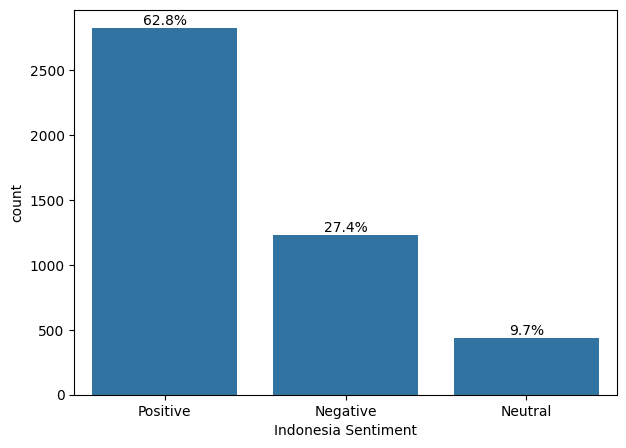

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(7, 5));
g = sns.countplot(x='Indonesia Sentiment', data=df)

ax=g.axes
for p in ax.patches:
     ax.annotate(f"{p.get_height() * 100 / df.shape[0]:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
         ha='center', va='center', fontsize=10, color='black', rotation=0, xytext=(0, 5),
         textcoords='offset points')

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("Labelling.csv")

df

,Text Normalization,Polarity Score,Indonesia Sentiment
0,banjir distribusi mbg lancar presiden,13,Positive
1,presiden program mbg hati pasti distribusi lan...,16,Positive
2,surat presiden program mbg hadir wilayah dampa...,4,Positive
3,warga cemas presiden solusi program mbg jalan ...,4,Positive
4,warga dampak banen rencana salur mbg,-5,Negative
...,...,...,...
4489,semangat optimis generasi muda tumbuh komitmen...,6,Positive
4490,mbg target anak sekolah begitu salur sekolah b...,-17,Negative
4491,enggak alas enggak sehat program mbg presiden ...,7,Positive
4492,halah buzzer bajing mbg sekarang isi snack min...,-10,Negative


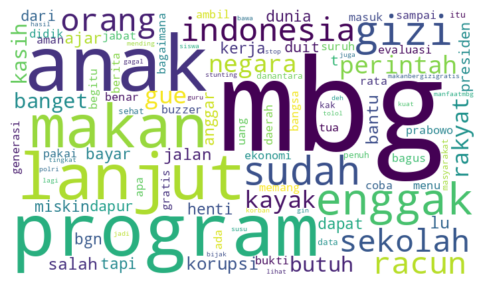

In [ ]:
from wordcloud import WordCloud,STOPWORDS
import matplotlib.pyplot as plt
import seaborn as sns

new_df=df[df['Indonesia Sentiment']=='Negative']
words = ' '.join(new_df['Text Normalization'])
wordcloud = WordCloud(stopwords=STOPWORDS,
                      background_color='white',
                      width=700, height=400, max_words = 100, collocations=False
                     ).generate(words)
plt.figure(figsize=(6, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis('off')
plt.show()

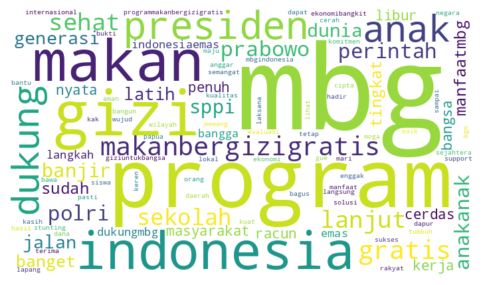

In [ ]:
from wordcloud import WordCloud,STOPWORDS
import matplotlib.pyplot as plt
import seaborn as sns

new_df=df[df['Indonesia Sentiment']=='Positive']
words = ' '.join(new_df['Text Normalization'])
wordcloud = WordCloud(stopwords=STOPWORDS,
                      background_color='white',
                      width=700, height=400, max_words = 100, collocations=False
                     ).generate(words)
plt.figure(figsize=(6, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis('off')
plt.show()

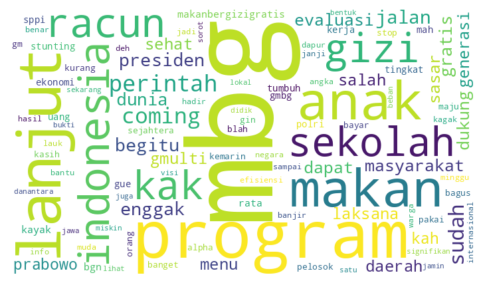

In [ ]:
from wordcloud import WordCloud,STOPWORDS
import matplotlib.pyplot as plt
import seaborn as sns

new_df=df[df['Indonesia Sentiment']=='Neutral']
words = ' '.join(new_df['Text Normalization'])
wordcloud = WordCloud(stopwords=STOPWORDS,
                      background_color='white',
                      width=700, height=400, max_words = 100, collocations=False
                     ).generate(words)
plt.figure(figsize=(6, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis('off')
plt.show()

# Annotate label

In [ ]:
label2id = {'Positive': 2, 'Neutral': 0, 'Negative': 1}
id2label = {v: k for k, v in label2id.items()}



In [ ]:
df['label'] = df['Indonesia Sentiment'].map(label2id)
df['text'] = df['Text Normalization']

# Tokenizing

In [ ]:
!pip install transformers
!pip install pandas scikit-learn

In [ ]:
import torch
from transformers import BertTokenizer, AutoModel
tokenizer = BertTokenizer.from_pretrained("indobenchmark/indobert-base-p2")
model = AutoModel.from_pretrained("indobenchmark/indobert-base-p2")

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/498M [00:00<?, ?B/s]

In [ ]:
# texts = df['text'].apply(lambda tokens: ' '.join(tokens)).tolist()
encodings = tokenizer(df["text"].tolist(), truncation=True, padding=True)
encodings

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


{'input_ids': [[2, 5138, 6413, 2201, 30365, 4843, 1871, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [2, 1871, 986, 2201, 30365, 1268, 1195, 6413, 4843, 5138, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [2, 1387, 1871, 986, 2201, 30365, 2505, 1350, 3345, 5138, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [2, 1470, 10424, 1871, 3196, 986, 2201, 30365, 795, 5138, 1036, 30354, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [2, 1470, 3345, 207, 9, 2596, 866, 58, 2201, 30365, 3, 0, 0, 0, 0,

In [ ]:
encodings

{'input_ids': [[2, 5138, 6413, 2201, 30365, 4843, 1871, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [2, 1871, 986, 2201, 30365, 1268, 1195, 6413, 4843, 5138, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [2, 1387, 1871, 986, 2201, 30365, 2505, 1350, 3345, 5138, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [2, 1470, 10424, 1871, 3196, 986, 2201, 30365, 795, 5138, 1036, 30354, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [2, 1470, 3345, 207, 9, 2596, 866, 58, 2201, 30365, 3, 0, 0, 0, 0,

# Split Data

In [ ]:
from sklearn.model_selection import train_test_split

train_idx, val_idx = train_test_split(list(range(len(df))), test_size=0.2, random_state=42)

train_texts = {key: [val[i] for i in train_idx] for key, val in encodings.items()}
val_texts = {key: [val[i] for i in val_idx] for key, val in encodings.items()}

train_labels = [df["label"].iloc[i] for i in train_idx]
val_labels = [df["label"].iloc[i] for i in val_idx]


print("Train Data:", len(train_labels))
print("Test Data:", len(val_labels))


Train Data: 3595
Test Data: 899


In [ ]:
df[['text', 'label']]

,text,label
0,banjir distribusi mbg lancar presiden,2
1,presiden program mbg hati pasti distribusi lan...,2
2,surat presiden program mbg hadir wilayah dampa...,2
3,warga cemas presiden solusi program mbg jalan ...,2
4,warga dampak banen rencana salur mbg,1
...,...,...
4489,semangat optimis generasi muda tumbuh komitmen...,2
4490,mbg target anak sekolah begitu salur sekolah b...,1
4491,enggak alas enggak sehat program mbg presiden ...,2
4492,halah buzzer bajing mbg sekarang isi snack min...,1


# Mengubah data ke PyTorch

In [ ]:
import torch

class MBGDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item
    def __len__(self):
        return len(self.labels)

train_dataset = MBGDataset(train_texts, train_labels)
val_dataset = MBGDataset(val_texts, val_labels)


# Modelling Indobert with Bayes Optimization

## Running Bayes Optuna

In [ ]:
!pip install optuna

from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
import optuna
from optuna.visualization import plot_optimization_history, plot_param_importances

def model_init():
    return AutoModelForSequenceClassification.from_pretrained(
        "indobenchmark/indobert-base-p2",
        num_labels=3,
        id2label=id2label,
        label2id=label2id
    )


In [ ]:
base_training_args = TrainingArguments(
    output_dir='./results-bayes-opt',
    logging_strategy='epoch',
    save_strategy='epoch',
    eval_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='f1',
    report_to="none"
)

def hp_space(trial):
    return {
        "learning_rate": trial.suggest_float("learning_rate", 1e-5, 2e-5, log=True),
        "per_device_train_batch_size": trial.suggest_categorical("per_device_train_batch_size", [8, 16]),
        "weight_decay": trial.suggest_float("weight_decay", 0.0, 0.3),
    }


In [ ]:
trainer_bayes = Trainer(
    model_init=model_init,
    args=base_training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics
)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
best_run = trainer_bayes.hyperparameter_search(
    direction="maximize",
    backend="optuna",
    hp_space=hp_space,
    n_trials=10,
    n_jobs=1,
    study_name="indobert-mbg-study"
)


[I 2025-08-16 08:44:59,254] A new study created in memory with name: indobert-mbg-study
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.643800,0.580888,0.778643,0.769369
2,0.437900,0.581652,0.803115,0.797952
3,0.326800,0.680064,0.805339,0.799746


[I 2025-08-16 08:47:28,914] Trial 0 finished with value: 1.6050851172401677 and parameters: {'learning_rate': 1.0212358906494649e-05, 'per_device_train_batch_size': 8, 'weight_decay': 0.013337317729977271}. Best is trial 0 with value: 1.6050851172401677.
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.638000,0.593102,0.775306,0.763656
2,0.426500,0.576223,0.786429,0.776414
3,0.300500,0.587625,0.795328,0.787847


[I 2025-08-16 08:49:09,409] Trial 1 finished with value: 1.5831750514950433 and parameters: {'learning_rate': 1.3319224434195015e-05, 'per_device_train_batch_size': 16, 'weight_decay': 0.2608607601611884}. Best is trial 0 with value: 1.6050851172401677.
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.643500,0.580341,0.778643,0.769369
2,0.436300,0.582307,0.802002,0.797081
3,0.321700,0.683926,0.805339,0.799300


... (11 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.637300,0.563801,0.780868,0.772726


[I 2025-08-16 08:58:21,852] Trial 8 pruned. 
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.643700,0.580563,0.777531,0.768371


[I 2025-08-16 08:59:06,090] Trial 9 pruned. 


In [ ]:
print("Best trial:")
print(f"  Run ID: {best_run.run_id}")
print(f"  Objective Score: {best_run.objective}")
for param_name, param_value in best_run.hyperparameters.items():
    print(f"    {param_name}: {param_value}")


Best trial:
  Run ID: 3
  Objective Score: 1.613828911424295
    learning_rate: 1.9082409978453484e-05
    per_device_train_batch_size: 8
    weight_decay: 0.046427779776890554


## Remove Cache
Menghapus folder pencarian hyperparameter

In [ ]:
!rm -rf mbg-sentiment-indobert/

## Train model

In [ ]:
optimized_training_args = TrainingArguments(
    output_dir="./results-model_bayes",
    eval_strategy='epoch',
    logging_strategy='epoch',
    save_strategy='epoch',
    learning_rate=best_run.hyperparameters["learning_rate"],
    per_device_train_batch_size=best_run.hyperparameters["per_device_train_batch_size"],
    num_train_epochs= 25,
    weight_decay=best_run.hyperparameters["weight_decay"],
    load_best_model_at_end=True,
    metric_for_best_model='f1',
    report_to="none"
)


In [ ]:
trainer_bayes = Trainer(
    model_init=model_init,
    args=optimized_training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
print(model)

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(50000, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e

In [ ]:
trainer_bayes.train()

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.635200,0.528933,0.781980,0.776711
2,0.434200,0.575785,0.818687,0.810882
3,0.296400,0.753333,0.802002,0.799818
4,0.192400,1.075321,0.819800,0.809402
5,0.122800,1.257545,0.803115,0.804610
6,0.088300,1.351474,0.807564,0.806268
7,0.061500,1.459917,0.808676,0.802146
8,0.027400,1.564677,0.808676,0.804576
9,0.025800,1.511495,0.815350,0.810465
10,0.016100,1.622449,0.807564,0.803215


TrainOutput(global_step=11250, training_loss=0.08108822948212425, metrics={'train_runtime': 1164.4195, 'train_samples_per_second': 77.184, 'train_steps_per_second': 9.661, 'total_flos': 3094473308645250.0, 'train_loss': 0.08108822948212425, 'epoch': 25.0})

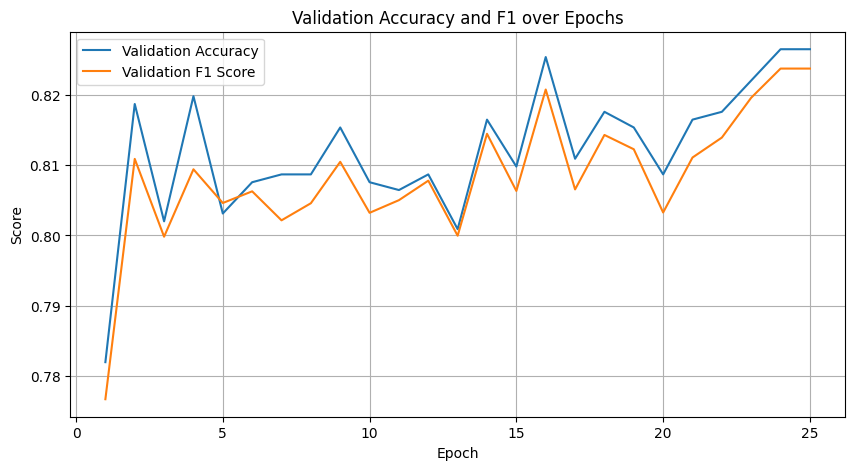

In [ ]:
import matplotlib.pyplot as plt

# Collect logs
log_history = trainer_bayes.state.log_history

# Separate logs by key
train_loss = []
eval_loss = []
eval_accuracy = []
eval_f1 = []
epochs = []

for log in log_history:
    if 'loss' in log and 'epoch' in log:
        train_loss.append(log['loss'])
        epochs.append(log['epoch'])
    if 'eval_loss' in log:
        eval_loss.append(log['eval_loss'])
    if 'eval_accuracy' in log:
        eval_accuracy.append(log['eval_accuracy'])
    if 'eval_f1' in log:
        eval_f1.append(log['eval_f1'])


# Plot Accuracy & F1
plt.figure(figsize=(10, 5))
plt.plot(epochs, eval_accuracy, label="Validation Accuracy")
plt.plot(epochs, eval_f1, label="Validation F1 Score")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Accuracy and F1 over Epochs")
plt.legend()
plt.grid(True)
plt.show()


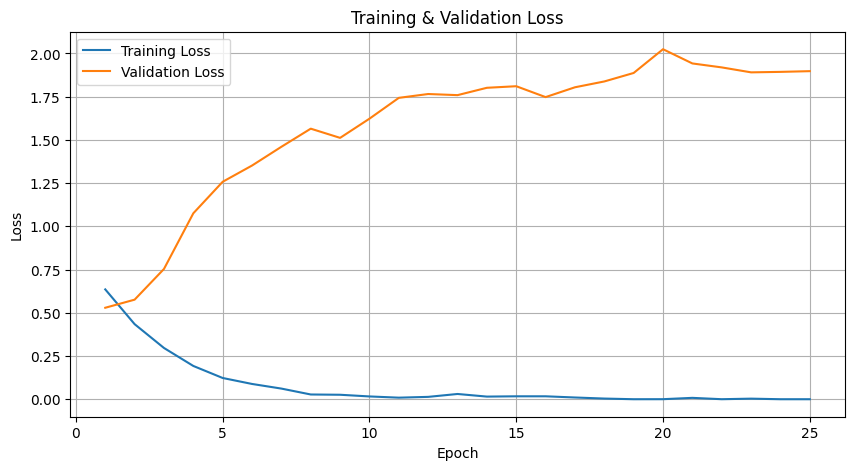

In [ ]:
# Plot Loss
plt.figure(figsize=(10, 5))
plt.plot(epochs, train_loss, label="Training Loss")
plt.plot(epochs, eval_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


## Evaluate Model

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay


In [ ]:
bayes_predictions = trainer_bayes.predict(val_dataset)
y_true = val_labels
y_pred_bayes = bayes_predictions.predictions.argmax(-1)

In [ ]:
eval_bayes = classification_report(
    y_true, y_pred_bayes, target_names=list(label2id.keys()), output_dict=True
)


In [ ]:
print(eval_bayes)

              precision    recall  f1-score   support

    Positive       0.72      0.55      0.63        94
     Neutral       0.75      0.77      0.76       250
    Negative       0.87      0.90      0.88       555

    accuracy                           0.83       899
   macro avg       0.78      0.74      0.76       899
weighted avg       0.82      0.83      0.82       899



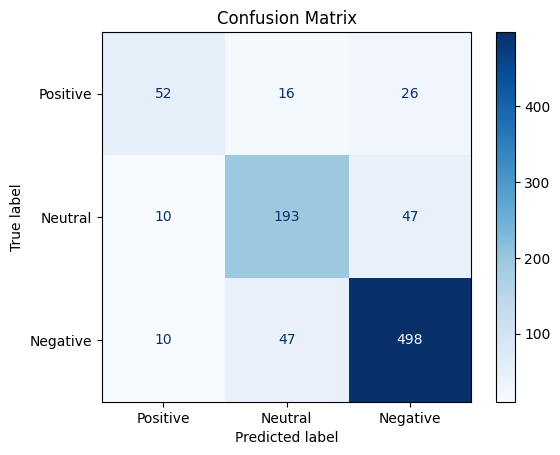

In [ ]:
cm = confusion_matrix(y_true, y_pred_bayes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(label2id.keys()))
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

## Test Model

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

model_name = "results-model_bayes"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

config.json:   0%|          | 0.00/995 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/498M [00:00<?, ?B/s]

In [ ]:
sentiment_analyzer = pipeline("text-classification", model=model, tokenizer=tokenizer)

Device set to use cuda:0


In [ ]:
result = sentiment_analyzer("makan gratis untuk anak sd tidak berguna")
print(result)


[{'label': 'Negative', 'score': 0.4343688189983368}]


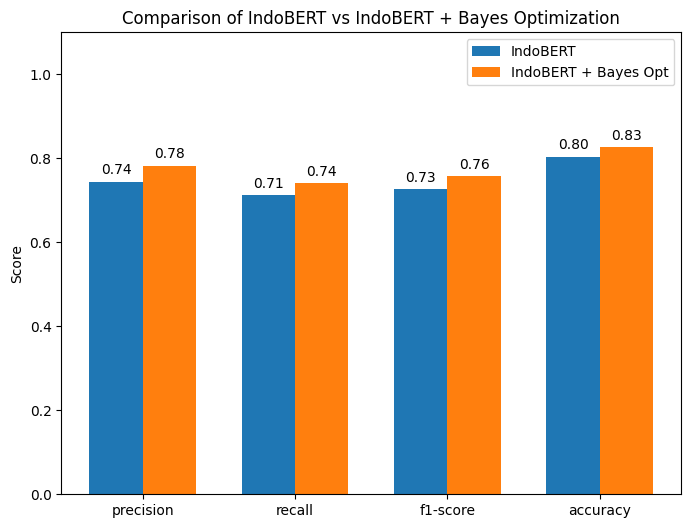

In [ ]:
!metrics = ["precision", "recall", "f1-score", "accuracy"]

indobert_scores = [
    eval_indobert["macro avg"]["precision"],
    eval_indobert["macro avg"]["recall"],
    eval_indobert["macro avg"]["f1-score"],
    eval_indobert["accuracy"]
]

bayes_scores = [
    eval_bayes["macro avg"]["precision"],
    eval_bayes["macro avg"]["recall"],
    eval_bayes["macro avg"]["f1-score"],
    eval_bayes["accuracy"]
]

# Plotting
x = np.arange(len(metrics))  # label locations
width = 0.35  # width of bars

fig, ax = plt.subplots(figsize=(8,6))
bars1 = ax.bar(x - width/2, indobert_scores, width, label="IndoBERT")
bars2 = ax.bar(x + width/2, bayes_scores, width, label="IndoBERT + Bayes Opt")

# Labels, title, legend
ax.set_ylabel("Score")
ax.set_title("Comparison of IndoBERT vs IndoBERT + Bayes Optimization")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()

# Annotate scores on top of bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f"{height:.2f}",
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha="center", va="bottom")

plt.ylim(0, 1.1)  # since scores are between 0 and 1
plt.show()
